# Лабораторная работа №7

## Задание 1.3. Загрузка данных и первичный обзор структуры

In [1]:
from pathlib import Path

import pandas as pd

project_dir = Path.cwd()
if not (project_dir / "data" / "raw_dataset.csv").is_file():
    project_dir = project_dir.parent

raw_df = pd.read_csv(project_dir / "data" / "raw_dataset.csv")
raw_df.shape

(23412, 21)

In [2]:
raw_df.head()

,Date,Time,Latitude,Longitude,Type,Depth,Depth Error,Depth Seismic Stations,Magnitude,Magnitude Type,...,Magnitude Seismic Stations,Azimuthal Gap,Horizontal Distance,Horizontal Error,Root Mean Square,ID,Source,Location Source,Magnitude Source,Status
0,01/02/1965,13:44:18,19.246,145.616,Earthquake,131.6,NaN,NaN,6.0,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860706,ISCGEM,ISCGEM,ISCGEM,Automatic
1,01/04/1965,11:29:49,1.863,127.352,Earthquake,80.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860737,ISCGEM,ISCGEM,ISCGEM,Automatic
2,01/05/1965,18:05:58,-20.579,-173.972,Earthquake,20.0,NaN,NaN,6.2,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860762,ISCGEM,ISCGEM,ISCGEM,Automatic
3,01/08/1965,18:49:43,-59.076,-23.557,Earthquake,15.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860856,ISCGEM,ISCGEM,ISCGEM,Automatic
4,01/09/1965,13:32:50,11.938,126.427,Earthquake,15.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860890,ISCGEM,ISCGEM,ISCGEM,Automatic


In [3]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23412 entries, 0 to 23411
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Date                        23412 non-null  object 
 1   Time                        23412 non-null  object 
 2   Latitude                    23412 non-null  float64
 3   Longitude                   23412 non-null  float64
 4   Type                        23412 non-null  object 
 5   Depth                       23412 non-null  float64
 6   Depth Error                 4461 non-null   float64
 7   Depth Seismic Stations      7097 non-null   float64
 8   Magnitude                   23412 non-null  float64
 9   Magnitude Type              23409 non-null  object 
 10  Magnitude Error             327 non-null    float64
 11  Magnitude Seismic Stations  2564 non-null   float64
 12  Azimuthal Gap               7299 non-null   float64
 13  Horizontal Distance         160

In [4]:
raw_df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,23412,12401,03/11/2011,128,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time,23412,20472,02:56:58,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Latitude,23412.0,NaN,NaN,NaN,1.679033,30.113183,-77.08,-18.653,-3.5685,26.19075,86.005
Longitude,23412.0,NaN,NaN,NaN,39.639961,125.511959,-179.997,-76.34975,103.982,145.02625,179.998
Type,23412,4,Earthquake,23232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Depth,23412.0,NaN,NaN,NaN,70.767911,122.651898,-1.1,14.5225,33.0,54.0,700.0
Depth Error,4461.0,NaN,NaN,NaN,4.993115,4.875184,0.0,1.8,3.5,6.3,91.295
Depth Seismic Stations,7097.0,NaN,NaN,NaN,275.364098,162.141631,0.0,146.0,255.0,384.0,934.0
Magnitude,23412.0,NaN,NaN,NaN,5.882531,0.423066,5.5,5.6,5.7,6.0,9.1
Magnitude Type,23409,10,MW,7722,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
raw_df.dtypes.to_frame("Тип данных")

,Тип данных
Date,object
Time,object
Latitude,float64
Longitude,float64
Type,object
Depth,float64
Depth Error,float64
Depth Seismic Stations,float64
Magnitude,float64
Magnitude Type,object


## Задание 1.4. Очистка данных

In [6]:
raw_df.isna().sum().to_frame("Пропуски")

,Пропуски
Date,0
Time,0
Latitude,0
Longitude,0
Type,0
Depth,0
Depth Error,18951
Depth Seismic Stations,16315
Magnitude,0
Magnitude Type,3


In [7]:
pd.Series({
    "Полные дубликаты": raw_df.duplicated().sum(),
    "Повторяющиеся идентификаторы": raw_df["ID"].duplicated().sum()
}).to_frame("Количество")

,Количество
Полные дубликаты,0
Повторяющиеся идентификаторы,0


In [8]:
raw_df["Type"].value_counts().to_frame("Число записей")

,Число записей
Type,
Earthquake,23232
Nuclear Explosion,175
Explosion,4
Rock Burst,1


In [9]:
raw_df["Date"].str.len().value_counts().sort_index().to_frame("Число записей")

,Число записей
Date,
10,23409
24,3


In [10]:
df = raw_df.copy()
is_iso = df["Date"].str.contains("T", na=False)
parsed_dates = pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns]")
parsed_dates.loc[~is_iso] = pd.to_datetime(df.loc[~is_iso, "Date"], format="%m/%d/%Y", errors="coerce")
parsed_dates.loc[is_iso] = pd.to_datetime(df.loc[is_iso, "Date"], format="%Y-%m-%dT%H:%M:%S.%fZ", errors="coerce")
df["Date"] = parsed_dates.dt.normalize()

for column in ["Latitude", "Longitude", "Depth", "Magnitude"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

pd.Series({
    "Даты без результата преобразования": df["Date"].isna().sum(),
    "Магнитуда ниже 5,5": df["Magnitude"].lt(5.5).sum()
}).to_frame("Количество")

,Количество
Даты без результата преобразования,0
"Магнитуда ниже 5,5",0


In [11]:
initial_count = len(df)
df = df.drop_duplicates().copy()
duplicate_count = initial_count - len(df)

other_type_count = df["Type"].ne("Earthquake").sum()
df = df.loc[df["Type"].eq("Earthquake")].copy()

required_columns = ["ID", "Date", "Latitude", "Longitude", "Magnitude", "Depth"]
before_required = len(df)
df = df.dropna(subset=required_columns).copy()
missing_count = before_required - len(df)

below_threshold_count = df["Magnitude"].lt(5.5).sum()
df = df.loc[df["Magnitude"].ge(5.5)].copy()
df["Year"] = df["Date"].dt.year
df = df.sort_values(["Date", "ID"]).reset_index(drop=True)

pd.Series({
    "Исходные записи": initial_count,
    "Удалены полные дубликаты": duplicate_count,
    "Исключены другие типы событий": other_type_count,
    "Исключены пропуски обязательных полей": missing_count,
    "Исключена магнитуда ниже 5,5": below_threshold_count,
    "Всего исключено": initial_count - len(df),
    "Осталось землетрясений": len(df)
}).to_frame("Количество")

,Количество
Исходные записи,23412
Удалены полные дубликаты,0
Исключены другие типы событий,180
Исключены пропуски обязательных полей,0
"Исключена магнитуда ниже 5,5",0
Всего исключено,180
Осталось землетрясений,23232


In [12]:
df[required_columns + ["Type", "Year"]].dtypes.to_frame("Тип данных после очистки")

,Тип данных после очистки
ID,object
Date,datetime64[ns]
Latitude,float64
Longitude,float64
Magnitude,float64
Depth,float64
Type,object
Year,int32


In [13]:
df[required_columns].isna().sum().to_frame("Пропуски после очистки")

,Пропуски после очистки
ID,0
Date,0
Latitude,0
Longitude,0
Magnitude,0
Depth,0


In [14]:
df[["Date", "Year", "Magnitude", "Depth"]].describe()

,Date,Year,Magnitude,Depth
count,23232,23232.000000,23232.000000,23232.000000
mean,1993-03-20 21:07:33.719008256,1992.718018,5.882763,71.313913
min,1965-01-02 00:00:00,1965.000000,5.500000,-1.100000
25%,1981-06-20 00:00:00,1981.000000,5.600000,15.000000
50%,1994-02-15 00:00:00,1994.000000,5.700000,33.000000
75%,2005-10-13 06:00:00,2005.000000,6.000000,54.800000
max,2016-12-30 00:00:00,2016.000000,9.100000,700.000000
std,NaN,14.438853,0.424032,122.968384


## Задание 2.1. Анализ данных

In [15]:
import sqlite3

import numpy as np
import matplotlib.pyplot as plt

annual_counts = df.groupby("Year").size().rename("Число событий").to_frame()
annual_counts.index.name = "Год"
annual_counts

,Число событий
Год,
1965,339
1966,233
1967,255
1968,303
1969,322
1970,344
1971,386
1972,388
1973,394


In [16]:
with sqlite3.connect(":memory:") as connection:
    df[["Year", "Magnitude", "Depth"]].to_sql("earthquakes", connection, index=False)
    annual_sql = pd.read_sql_query(
        "SELECT Year AS year, COUNT(*) AS event_count "
        "FROM earthquakes GROUP BY Year ORDER BY Year",
        connection
    )

pd.Series({
    "Совпадение годовых чисел Pandas и SQL": np.array_equal(
        annual_counts["Число событий"].to_numpy(), annual_sql["event_count"].to_numpy()
    ),
    "Сумма годовых чисел": annual_sql["event_count"].sum()
}).to_frame("Результат")

,Результат
Совпадение годовых чисел Pandas и SQL,True
Сумма годовых чисел,23232


In [17]:
magnitude_bins = [5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 8.5, 9.0, 9.5]
magnitude_groups = pd.cut(df["Magnitude"], bins=magnitude_bins, right=False)
magnitude_counts = df.groupby(magnitude_groups, observed=False).size().rename("Число событий").to_frame()
magnitude_counts.index.name = "Интервал магнитуды"
magnitude_counts

,Число событий
Интервал магнитуды,
"[5.5, 6.0)",15936
"[6.0, 6.5)",4999
"[6.5, 7.0)",1559
"[7.0, 7.5)",515
"[7.5, 8.0)",183
"[8.0, 8.5)",34
"[8.5, 9.0)",4
"[9.0, 9.5)",2


In [18]:
pd.Series({
    "Первый год": df["Year"].min(),
    "Последний год": df["Year"].max(),
    "Год с наименьшим числом событий": annual_counts["Число событий"].idxmin(),
    "Минимальное годовое число": annual_counts["Число событий"].min(),
    "Год с наибольшим числом событий": annual_counts["Число событий"].idxmax(),
    "Максимальное годовое число": annual_counts["Число событий"].max(),
    "Медиана магнитуды": df["Magnitude"].median(),
    "Доля магнитуд от 5,5 до 6,0": df["Magnitude"].lt(6.0).mean(),
    "Медиана глубины, км": df["Depth"].median(),
    "Минимальная глубина, км": df["Depth"].min(),
    "Максимальная глубина, км": df["Depth"].max(),
    "Корреляция Пирсона: магнитуда и глубина": df["Magnitude"].corr(df["Depth"])
}).to_frame("Значение")

,Значение
Первый год,1965.000000
Последний год,2016.000000
Год с наименьшим числом событий,1966.000000
Минимальное годовое число,233.000000
Год с наибольшим числом событий,2011.000000
Максимальное годовое число,713.000000
Медиана магнитуды,5.700000
"Доля магнитуд от 5,5 до 6,0",0.685950
"Медиана глубины, км",33.000000
"Минимальная глубина, км",-1.100000


## Задание 2.2. Визуализация данных

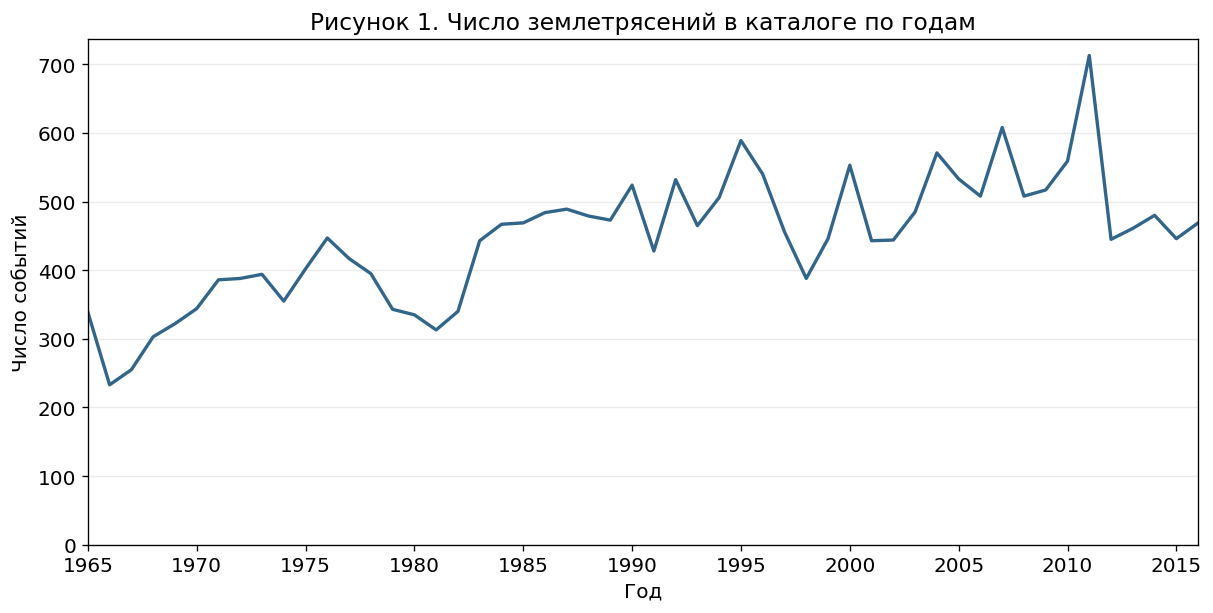

In [19]:
plt.rcParams.update({"font.size": 12, "axes.titlesize": 14, "figure.dpi": 120})

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
ax.plot(annual_counts.index, annual_counts["Число событий"], color="#32658a", linewidth=2)
ax.set(title="Рисунок 1. Число землетрясений в каталоге по годам", xlabel="Год", ylabel="Число событий")
ax.set_xticks(range(1965, 2017, 5))
ax.set_xlim(1965, 2016)
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.25)
plt.show()

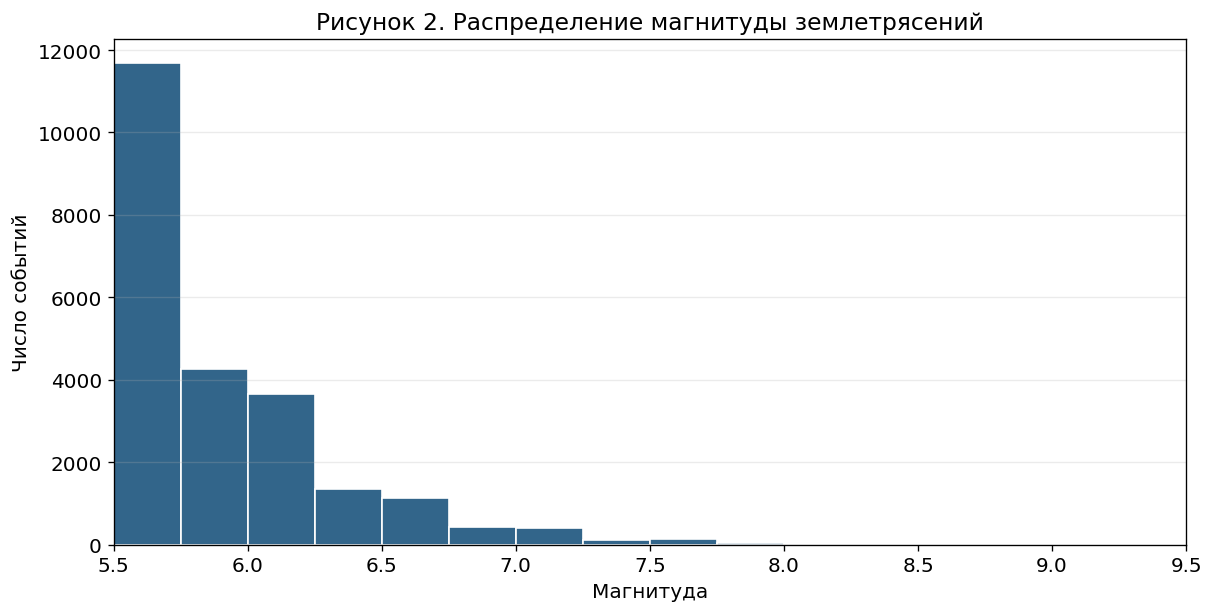

In [20]:
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
ax.hist(df["Magnitude"], bins=np.arange(5.5, 9.6, 0.25), color="#32658a", edgecolor="white")
ax.set(title="Рисунок 2. Распределение магнитуды землетрясений", xlabel="Магнитуда", ylabel="Число событий")
ax.set_xticks(np.arange(5.5, 9.6, 0.5))
ax.set_xlim(5.5, 9.5)
ax.grid(axis="y", alpha=0.25)
plt.show()

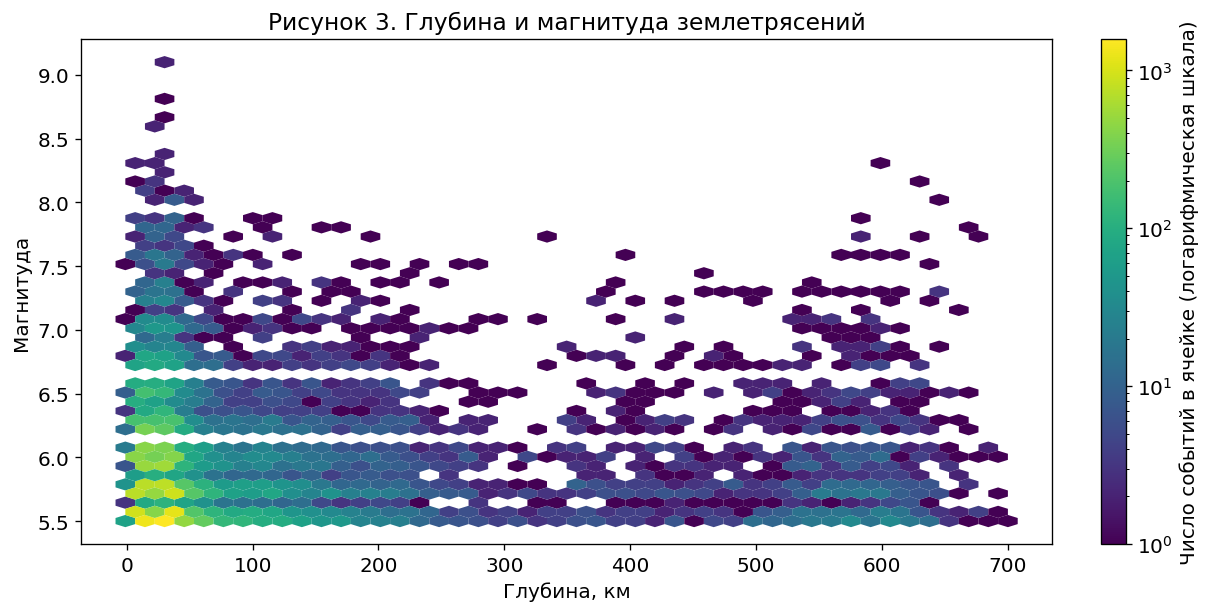

In [21]:
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
density = ax.hexbin(df["Depth"], df["Magnitude"], gridsize=45, mincnt=1, bins="log", cmap="viridis", linewidths=0)
fig.colorbar(density, ax=ax, label="Число событий в ячейке (логарифмическая шкала)")
ax.set(title="Рисунок 3. Глубина и магнитуда землетрясений", xlabel="Глубина, км", ylabel="Магнитуда")
plt.show()

## Задание 2.4. Выводы

В выбранном каталоге за 1965–2016 годы после отбора событий типа Earthquake осталось 23 232 землетрясения с магнитудой от 5,5.
Как показывает рисунок 1 в [задании 2.2](#Задание-2.2.-Визуализация-данных), годовое число событий колебалось от 233 в 1966 году до 713 в 2011 году, при этом равномерного роста не наблюдалось.
На рисунке 2 в [задании 2.2](#Задание-2.2.-Визуализация-данных) преобладают небольшие для этого каталога магнитуды: 68,6 % событий имеют магнитуду от 5,5 включительно до 6,0, медиана составляет 5,7.
Рисунок 3 в [задании 2.2](#Задание-2.2.-Визуализация-данных) показывает наибольшую плотность наблюдений при небольших глубинах и магнитудах, а коэффициент Пирсона около 0,023 в итоговой таблице [задания 2.1](#Задание-2.1.-Анализ-данных) указывает на почти отсутствующую линейную связь глубины и магнитуды.
Годовые числа, полученные группировкой Pandas и SQL-запросом в [задании 2.1](#Задание-2.1.-Анализ-данных), совпали.
Эти результаты описывают записи выбранного каталога, не характеризуют все землетрясения и не доказывают причинных связей.